In [38]:
from google.colab import files

uploaded = files.upload()

Saving dataset.csv to dataset (1).csv


In [39]:
import pandas as pd
import numpy as np

filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (1500, 17)


In [40]:
display(df.head())

,student_id,gender,age,branch,previous_semester_gpa,attendance_percentage,study_hours_per_day,backlogs_count,extracurricular_participation,internship_completed,coding_practice_hours_per_week,num_certifications,internal_assessment_score,communication_skill_score,family_income_bracket,cgpa_final,placement
0,STU00001,Female,21,CIVIL,7.31,80.1,3.14,0,0,0,8.83,2,35.9,55.4,Medium,7.00,1
1,STU00002,Female,22,ECE,6.83,67.1,2.15,1,0,1,14.75,1,47.8,53.6,Low,6.15,1
2,STU00003,Male,21,IT,NaN,69.6,2.88,1,1,0,10.31,1,32.9,57.8,Medium,5.57,0
3,STU00004,Male,21,MECH,7.01,55.3,2.63,1,1,1,5.87,2,45.3,74.7,Medium,6.01,0
4,STU00005,Female,20,CSE,5.90,64.8,4.60,0,0,1,1.46,2,25.9,33.2,Low,6.19,0


In [41]:
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

Number of Rows: 1500
Number of Columns: 17


In [42]:
print(df.columns.tolist())

['student_id', 'gender', 'age', 'branch', 'previous_semester_gpa', 'attendance_percentage', 'study_hours_per_day', 'backlogs_count', 'extracurricular_participation', 'internship_completed', 'coding_practice_hours_per_week', 'num_certifications', 'internal_assessment_score', 'communication_skill_score', 'family_income_bracket', 'cgpa_final', 'placement']


In [43]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 17 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   student_id                      1500 non-null   object 
 1   gender                          1500 non-null   object 
 2   age                             1500 non-null   int64  
 3   branch                          1500 non-null   object 
 4   previous_semester_gpa           1454 non-null   float64
 5   attendance_percentage           1500 non-null   float64
 6   study_hours_per_day             1500 non-null   float64
 7   backlogs_count                  1500 non-null   int64  
 8   extracurricular_participation   1500 non-null   int64  
 9   internship_completed            1500 non-null   int64  
 10  coding_practice_hours_per_week  1500 non-null   float64
 11  num_certifications              1500 non-null   int64  
 12  internal_assessment_score       15

In [44]:
print(df.isnull().sum())

student_id                         0
gender                             0
age                                0
branch                             0
previous_semester_gpa             46
attendance_percentage              0
study_hours_per_day                0
backlogs_count                     0
extracurricular_participation      0
internship_completed               0
coding_practice_hours_per_week     0
num_certifications                 0
internal_assessment_score          0
communication_skill_score         45
family_income_bracket             86
cgpa_final                         0
placement                          0
dtype: int64


In [45]:
df.describe()

,age,previous_semester_gpa,attendance_percentage,study_hours_per_day,backlogs_count,extracurricular_participation,internship_completed,coding_practice_hours_per_week,num_certifications,internal_assessment_score,communication_skill_score,cgpa_final,placement
count,1500.000000,1454.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1500.000000,1455.000000,1500.000000,1500.000000
mean,20.462667,6.951039,78.433000,3.282000,0.208667,0.393333,0.393333,6.053660,1.164000,42.378667,60.197251,7.056033,0.456000
std,1.119572,0.990902,11.856018,1.560363,0.556175,0.488653,0.488653,3.815193,1.123957,10.431218,14.440739,0.860408,0.498226
min,19.000000,3.860000,35.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.600000,3.810000,0.000000
25%,19.000000,6.270000,70.500000,2.217500,0.000000,0.000000,0.000000,3.285000,0.000000,35.600000,50.800000,6.510000,0.000000
50%,20.000000,6.950000,78.400000,3.200000,0.000000,0.000000,0.000000,5.870000,1.000000,42.200000,59.900000,7.080000,0.000000
75%,21.000000,7.580000,86.900000,4.340000,0.000000,1.000000,1.000000,8.620000,2.000000,49.600000,69.900000,7.640000,1.000000
max,22.000000,10.000000,100.000000,9.740000,4.000000,1.000000,1.000000,19.740000,6.000000,79.200000,100.000000,10.000000,1.000000


In [46]:
print("Total Duplicate Rows:", df.duplicated().sum())

Total Duplicate Rows: 0


In [47]:
df_clean = df.copy()

df_clean = df_clean.drop_duplicates()


num_cols = df_clean.select_dtypes(
    include=np.number
).columns

for col in num_cols:
    df_clean[col] = df_clean[col].fillna(
        df_clean[col].median()
    )

cat_cols = df_clean.select_dtypes(
    include='object'
).columns

for col in cat_cols:
    if df_clean[col].notna().any():
        df_clean[col] = df_clean[col].fillna(
            df_clean[col].mode()[0]
        )

print("Missing values after cleaning:")
print(df_clean.isnull().sum().sum())

print("Duplicates after cleaning:",
      df_clean.duplicated().sum())

Missing values after cleaning:
0
Duplicates after cleaning: 0


In [48]:

print(df['placement'].value_counts())

placement
0    816
1    684
Name: count, dtype: int64


In [49]:
import matplotlib.pyplot as plt
import seaborn as sns

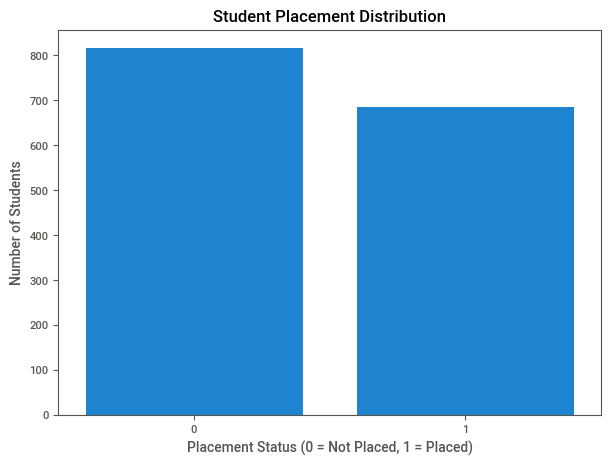

In [50]:
plt.figure(figsize=(7,5))

sns.countplot(data=df, x='placement')

plt.title('Student Placement Distribution')
plt.xlabel('Placement Status (0 = Not Placed, 1 = Placed)')
plt.ylabel('Number of Students')

plt.show()

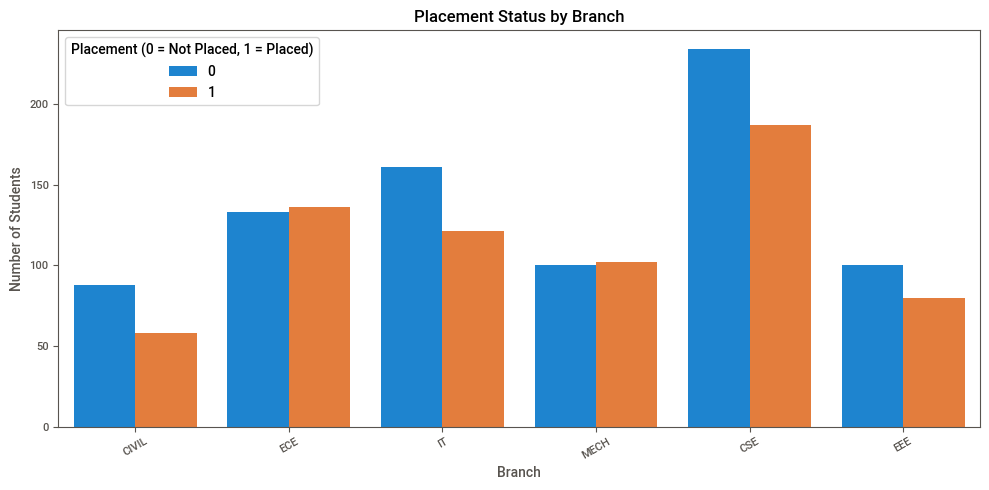

In [51]:
plt.figure(figsize=(10, 5))

sns.countplot(data=df, x='branch', hue='placement')

plt.title('Placement Status by Branch')
plt.xlabel('Branch')
plt.ylabel('Number of Students')
plt.xticks(rotation=30)
plt.legend(title='Placement (0 = Not Placed, 1 = Placed)')

plt.tight_layout()
plt.show()

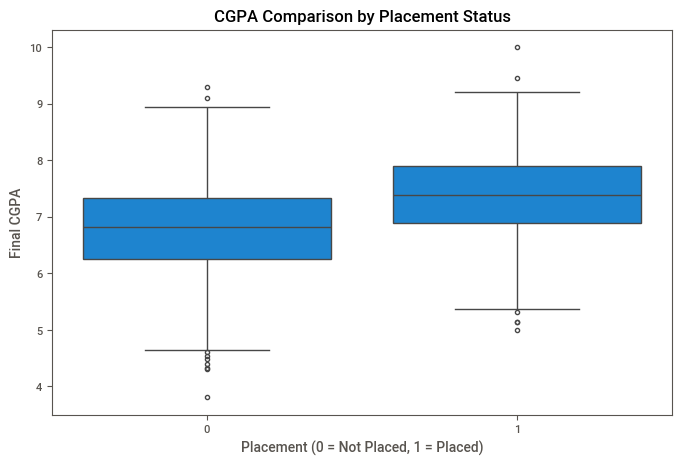

In [52]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='placement', y='cgpa_final')

plt.title('CGPA Comparison by Placement Status')
plt.xlabel('Placement (0 = Not Placed, 1 = Placed)')
plt.ylabel('Final CGPA')

plt.show()

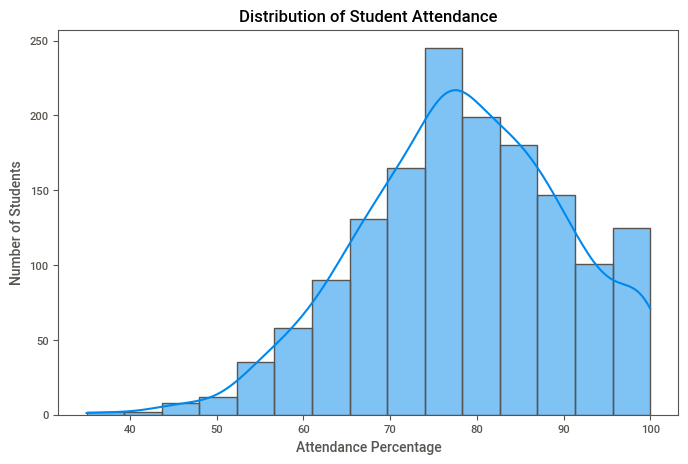

In [53]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='attendance_percentage', bins=15, kde=True)

plt.title('Distribution of Student Attendance')
plt.xlabel('Attendance Percentage')
plt.ylabel('Number of Students')

plt.show()

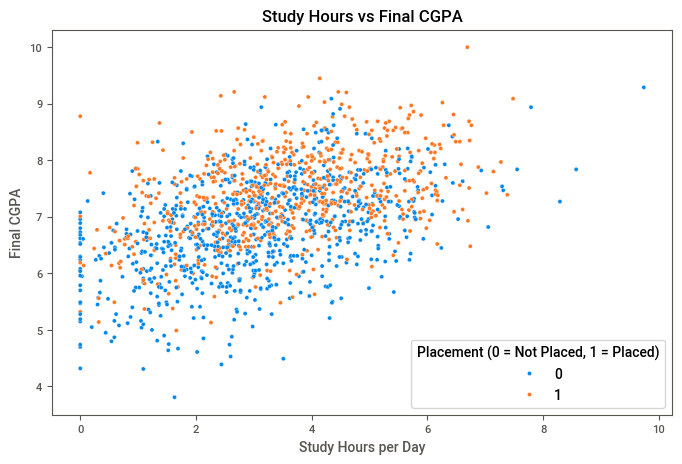

In [54]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='study_hours_per_day',
    y='cgpa_final',
    hue='placement'
)

plt.title('Study Hours vs Final CGPA')
plt.xlabel('Study Hours per Day')
plt.ylabel('Final CGPA')
plt.legend(title='Placement (0 = Not Placed, 1 = Placed)')

plt.show()

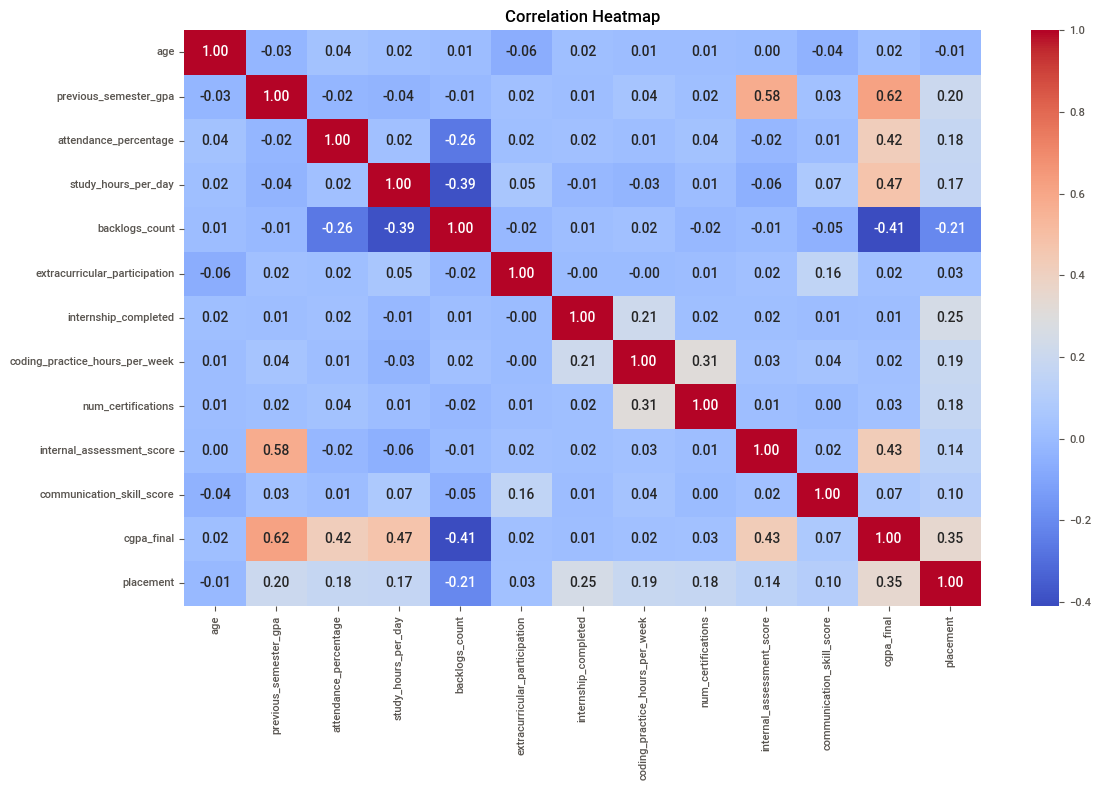

In [55]:
numeric_df = df_clean.select_dtypes(
    include=np.number
).drop(columns=['student_id'], errors='ignore')

plt.figure(figsize=(12, 8))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

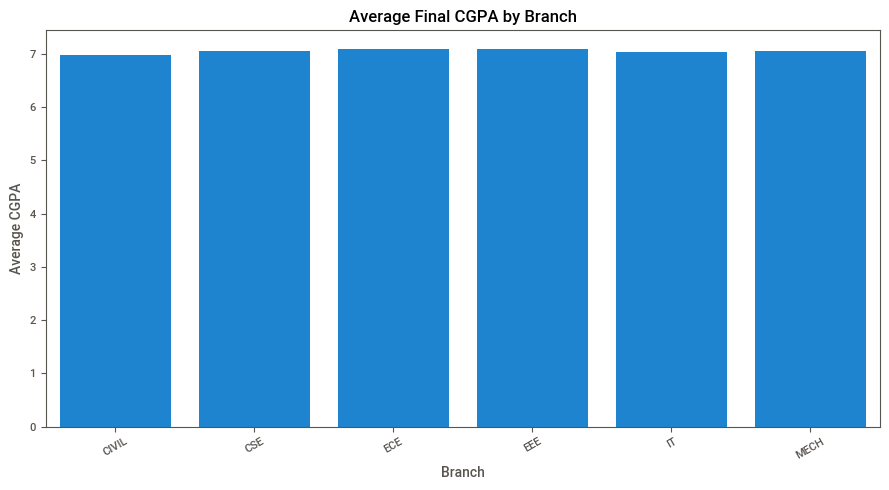

In [56]:
branch_cgpa = df.groupby('branch')['cgpa_final'].mean().reset_index()

plt.figure(figsize=(9, 5))

sns.barplot(data=branch_cgpa, x='branch', y='cgpa_final')

plt.title('Average Final CGPA by Branch')
plt.xlabel('Branch')
plt.ylabel('Average CGPA')
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

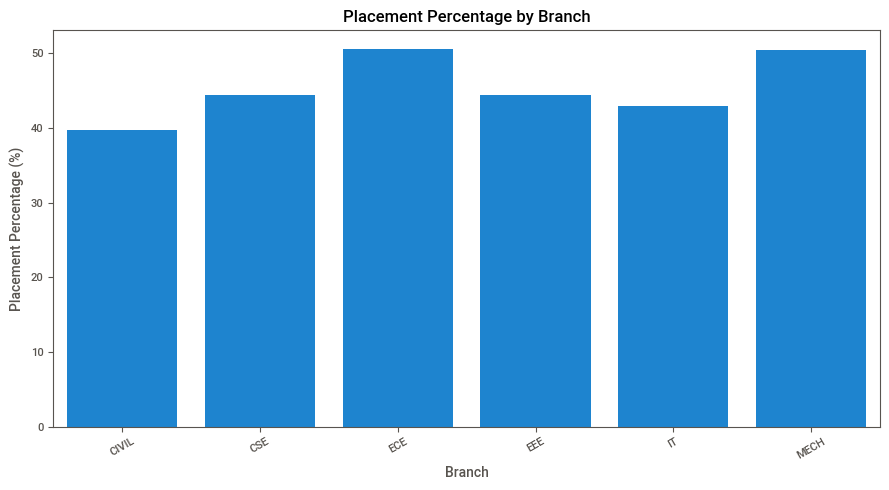

In [57]:
branch_placement = df.groupby('branch')['placement'].mean().reset_index()

branch_placement['placement'] = branch_placement['placement'] * 100

plt.figure(figsize=(9, 5))

sns.barplot(data=branch_placement, x='branch', y='placement')

plt.title('Placement Percentage by Branch')
plt.xlabel('Branch')
plt.ylabel('Placement Percentage (%)')
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

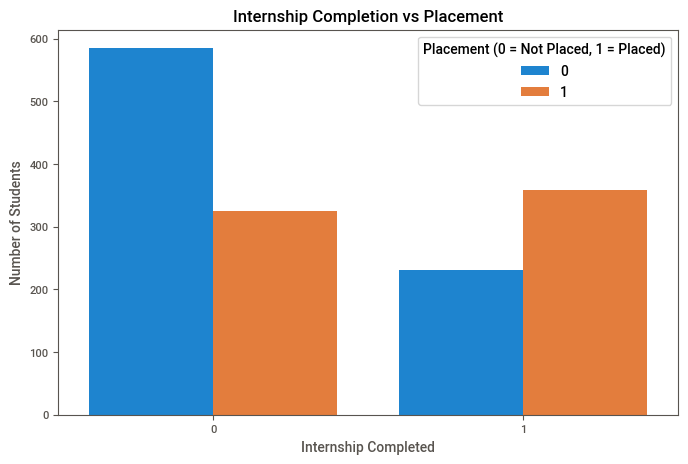

In [58]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='internship_completed', hue='placement')

plt.title('Internship Completion vs Placement')
plt.xlabel('Internship Completed')
plt.ylabel('Number of Students')
plt.legend(title='Placement (0 = Not Placed, 1 = Placed)')

plt.show()

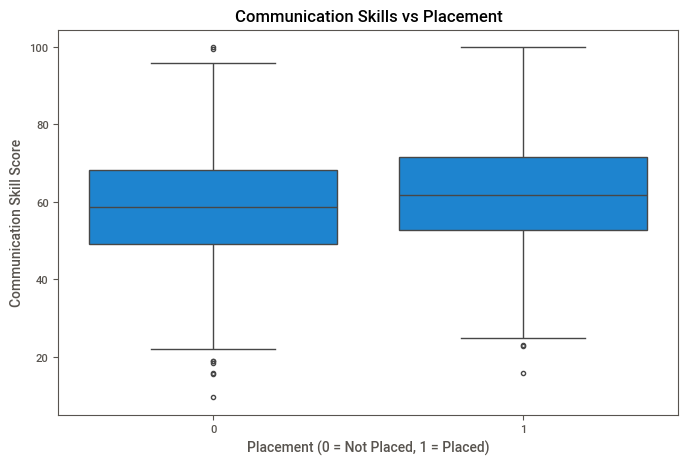

In [59]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='placement', y='communication_skill_score')

plt.title('Communication Skills vs Placement')
plt.xlabel('Placement (0 = Not Placed, 1 = Placed)')
plt.ylabel('Communication Skill Score')

plt.show()

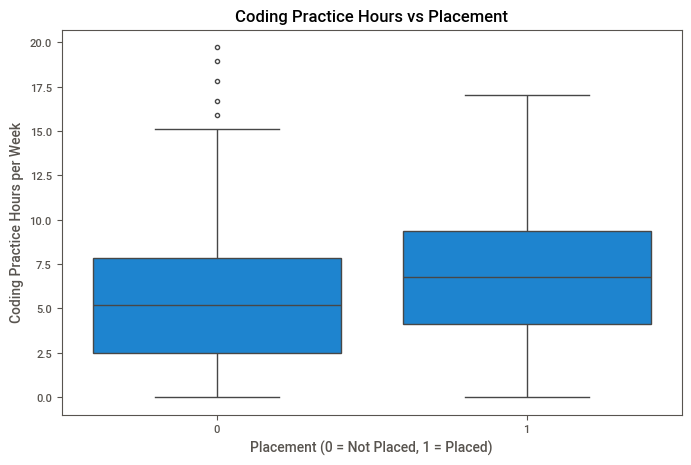

In [60]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='placement', y='coding_practice_hours_per_week')

plt.title('Coding Practice Hours vs Placement')
plt.xlabel('Placement (0 = Not Placed, 1 = Placed)')
plt.ylabel('Coding Practice Hours per Week')

plt.show()

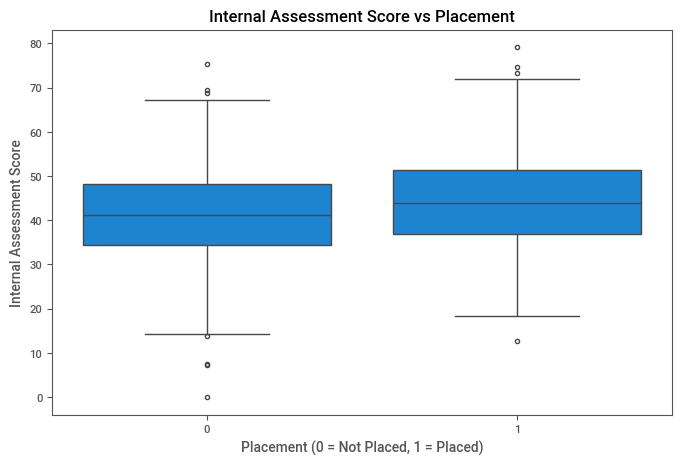

In [61]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='placement', y='internal_assessment_score')

plt.title('Internal Assessment Score vs Placement')
plt.xlabel('Placement (0 = Not Placed, 1 = Placed)')
plt.ylabel('Internal Assessment Score')

plt.show()

In [62]:
!pip install sweetviz

In [63]:
import sweetviz as sv

report = sv.analyze(df)

report.show_html("Student_Placement_Analysis.html")

                                             |          | [  0%]   00:00 -> (? left)

Report Student_Placement_Analysis.html was generated! NOTEBOOK/COLAB USERS: the web browser MAY not pop up, regardless, the report IS saved in your notebook/colab files.


In [64]:
from google.colab import files

files.download("Student_Placement_Analysis.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [67]:
from sklearn.ensemble import IsolationForest

features = df.select_dtypes(include=np.number).drop(
    columns=['student_id'], errors='ignore'
)
features = features.fillna(features.median())


model = IsolationForest(contamination=0.05, random_state=42)

df['anomaly'] = model.fit_predict(features)


print("Anomaly Detection Results:")
print(df['anomaly'].value_counts())

print("\n-1 = Unusual Records")
print(" 1 = Normal Records")

Anomaly Detection Results:
anomaly
 1    1425
-1      75
Name: count, dtype: int64

-1 = Unusual Records
 1 = Normal Records


In [68]:
normal = (df['anomaly'] == 1).sum()
unusual = (df['anomaly'] == -1).sum()

print("Total Students:", len(df))
print("Normal Records:", normal)
print("Unusual Records:", unusual)

print("Normal Percentage:", round(normal / len(df) * 100, 2), "%")
print("Unusual Percentage:", round(unusual / len(df) * 100, 2), "%")

Total Students: 1500
Normal Records: 1425
Unusual Records: 75
Normal Percentage: 95.0 %
Unusual Percentage: 5.0 %


In [69]:
from scipy.stats import f_oneway

placed_cgpa = df[df['placement'] == 1]['cgpa_final'].dropna()
not_placed_cgpa = df[df['placement'] == 0]['cgpa_final'].dropna()

f_stat, p_value = f_oneway(placed_cgpa, not_placed_cgpa)

print("ANOVA Results")
print("F-Statistic:", f_stat)
print("P-Value:", p_value)

if p_value < 0.05:
    print("Significant difference in average CGPA.")
else:
    print("No significant difference in average CGPA.")

ANOVA Results
F-Statistic: 210.02947710461672
P-Value: 1.2203956264190254e-44
Significant difference in average CGPA.


In [70]:
df_powerbi = df.copy()

# Remove anomaly column if it exists
df_powerbi = df_powerbi.drop(columns=['anomaly'], errors='ignore')

print("Dataset ready for Power BI!")
print("Shape:", df_powerbi.shape)

df_powerbi.head()

Dataset ready for Power BI!
Shape: (1500, 17)


,student_id,gender,age,branch,previous_semester_gpa,attendance_percentage,study_hours_per_day,backlogs_count,extracurricular_participation,internship_completed,coding_practice_hours_per_week,num_certifications,internal_assessment_score,communication_skill_score,family_income_bracket,cgpa_final,placement
0,STU00001,Female,21,CIVIL,7.31,80.1,3.14,0,0,0,8.83,2,35.9,55.4,Medium,7.00,1
1,STU00002,Female,22,ECE,6.83,67.1,2.15,1,0,1,14.75,1,47.8,53.6,Low,6.15,1
2,STU00003,Male,21,IT,NaN,69.6,2.88,1,1,0,10.31,1,32.9,57.8,Medium,5.57,0
3,STU00004,Male,21,MECH,7.01,55.3,2.63,1,1,1,5.87,2,45.3,74.7,Medium,6.01,0
4,STU00005,Female,20,CSE,5.90,64.8,4.60,0,0,1,1.46,2,25.9,33.2,Low,6.19,0


In [71]:
df_powerbi.to_csv("Student_Placement_Cleaned.csv", index=False)

print("Dataset exported successfully!")

Dataset exported successfully!


In [72]:
from google.colab import files

files.download("Student_Placement_Cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion

The Student Placement Analysis project helped us understand the factors that may be associated with student placement outcomes.

Using Python, Pandas, NumPy, Matplotlib, and Seaborn, we explored the dataset and created different visualizations to understand student performance.

Sweetviz was used to generate an automated data analysis report, and Isolation Forest was used to identify unusual records in the dataset.

The analysis explored factors such as CGPA, attendance, study hours, internship experience, communication skills, and coding practice.

Finally, the cleaned dataset was prepared for Power BI to create an interactive dashboard.

Overall, this project improved our understanding of data cleaning, data analysis, visualization, and data-driven decision-making.